# Plane Waves

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-01.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")

## Plane Waves in 2D - Animation
This code generates lines of constant phase for a plane wave in a 2D plot.

### Initialize libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

### Define variables
We need a list of values of x and y coordinates, as well as a time variable.  To avoid using nested `for` loops, we will use numpy's `meshgrid` function to create a grid of x and t values.  We will calculate the y values later for each combination of x and t.

In [2]:
k1 = (1.0, 1.0)  # wave vector / propagation direction
omega1 = 1.0  # angular frequency (to create a speed for propagation)
phi1 = np.arange(-2*np.pi, 4*np.pi,1)  # list of constant phase values to plot
numpoints1space = 64 # number of points in space
numpoints1time = 32 # number of time points
x1 = np.linspace(0, 2*np.pi, numpoints1space) # make list of x values
t1 = np.linspace(0, 2*np.pi, numpoints1time) # make list of t values
X1, PHI1, T1 = np.meshgrid(x1, phi1, t1, indexing='ij') # make grid of x, t, and phi values so no for loops are needed

### Create lines of constant phase
The equation for a plane wave traveling in the $\vec{k}$-direction is:
$$ \vec{E}=\vec{E}_0 e^{i (\vec{k}\cdot \vec{r} -\omega t)} =\vec{E}_0 e^{i (k_x x + k_y y -\omega t)}$$
The phase term $\phi$ is the expression in the exponential:
$$\phi = k_x x + k_y y -\omega t$$
For a given time $t$ and a particule coordinate $x$, lines of constant phase can be found by setting $\phi$ to a constant value.  Rearranging gives:
$$y = \frac{\phi + \omega t - k_x x}{k_y}$$

In [3]:
Y1 = (PHI1 + omega1*T1 - k1[0]*X1) / k1[1] # calculate meshgrid of y values for each combination of x, t, and phi
# print(np.shape(Y1))

### Plot lines of constant phase

<function matplotlib.pyplot.show(close=None, block=None)>

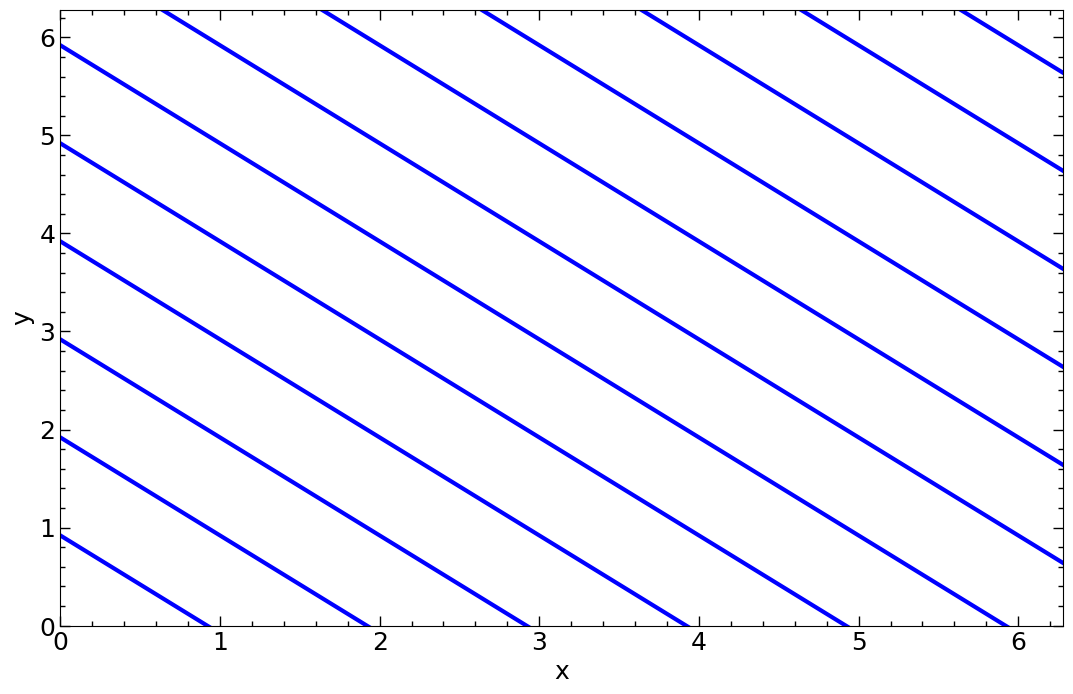

In [ ]:
# create a figure containing a single set of axes
fig1, ax1 = plt.subplots(figsize=(8*1.618,8))

# plot the graph on this set of axes
l1 = ax1.plot(X1[:,:,1],Y1[:,:,1])

# set the tick mark parameters
ax1.minorticks_on()
ax1.tick_params(which='both',direction="in",width=1)
ax1.tick_params(which='major',length=7)
ax1.tick_params(which='minor',length=3.5)
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')

# set axes limits
ax1.set_xlim(0, 2*np.pi)
ax1.set_ylim(0, 2*np.pi)

# label the axes
ax1.set_xlabel("x")
ax1.set_ylabel("y")

# change the appearance of the lines
plt.setp(l1, linewidth=3, color='b')  # line1 is thick and blue

# show the plot
plt.show

### Interactive plotting in Jupyter notebook
Use magic command `%matplotlib inline`

In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

# 1. Setup Parameters
k2 = (1.0, 1.0)
omega2 = 1.0
phi2 = np.arange(-2*np.pi, 4*np.pi, 1) # Phase array
x2 = np.linspace(0, 2*np.pi, 64)       # x array

# Static Grid
X2, PHI2 = np.meshgrid(x2, phi2, indexing='ij')

# 2. Setup Figure ONCE (No animation loop pre-calculation)
fig, ax = plt.subplots(figsize=(8, 5))
fig.canvas.header_visible = False
fig.canvas.footer_visible = False
ax.set_xlim(0, 2*np.pi)
ax.set_ylim(0, 2*np.pi)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True, alpha=0.3)

# Draw initial lines and save reference to them
# We calculate t=0 state just to initialize the objects
Y_init = (PHI2 + omega2*0 - k2[0]*X2) / k2[1]
lines = ax.plot(X2, Y_init, linewidth=2, color='b')

# 3. Define the fast update function
def update(time):
    # Calculate new positions for the specific time requested
    Y_current = (PHI2 + omega2*time - k2[0]*X2) / k2[1]
    
    # Update the data of existing lines (very fast)
    for line, y_col in zip(lines, Y_current.T):
        line.set_ydata(y_col)
    
    fig.canvas.draw_idle() # Request a redraw

# 4. Create Slider
slider = FloatSlider(min=0, max=2*np.pi, step=0.1, description='Time')
interact(update, time=slider);

### Run animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-01-planewave-2D_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-01.html) (direct link: [ch02-01-planewave-2D_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-01-planewave-2D_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.

## Plane Waves in 3D Plot
For memory management purposes, we will not store all the time values in an array.  Instead, we will first plot t=0 and then animate with a for loop later.

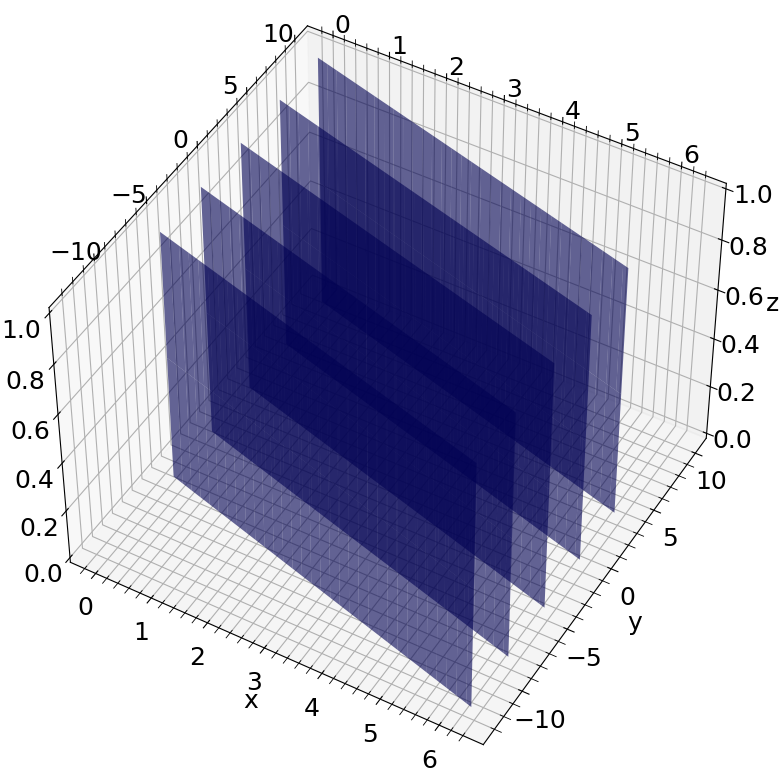

In [11]:
from mpl_toolkits.mplot3d import Axes3D

z1 = np.linspace(0, 1, 3) # make list of z values
X4, Z4 = np.meshgrid(x1, z1, indexing='ij') # make grid of x, z, and phi values

# create a figure containing a single set of axes
fig2 = plt.figure(figsize=(8*1.618,8))
ax2 = fig2.add_subplot(111, projection='3d')

# Plot each surface for a subset of phase values
for index1 in range(0, len(phi1), 4):  # plot every 4th phase value to reduce clutter
    Y4 = (phi1[index1] + omega1*0 - k1[0]*X4) / k1[1]
    ax2.plot_surface(X4,Y4,Z4, color='blue', alpha=0.6)

# Set labels and title
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_zlabel('z')
# ax2.set_title('3D Plane Wave with Multiple Phase Surfaces')

# set the tick mark parameters
ax2.minorticks_on()
ax2.tick_params(which='both',direction="in",width=1)
ax2.tick_params(which='major',length=7)
ax2.tick_params(which='minor',length=3.5)
ax2.xaxis.set_ticks_position('both')
ax2.yaxis.set_ticks_position('both')
ax2.zaxis.set_ticks_position('both')

# # set axes limits
# ax2.set_xlim(0, 2*np.pi)
# ax2.set_ylim(0, 2*np.pi)



ax2.view_init(elev=45, azim=-60)

# show the plot
plt.tight_layout()
plt.show()

### Interactive plotting in Jupyter notebook
Use magic command `%matplotlib inline`

In [ ]:
%matplotlib widget
import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import interact, FloatSlider

# --- 1. Define Data ---
x5 = np.linspace(0, 10, 20)

# CHANGE: Generate exactly 11 phase values so we get 11 planes
# I increased the range to 8*pi so the 11 planes are spread out nicely
phi5 = np.linspace(0, 10*np.pi, 10)

omega5 = 2.0
k5 = [1.0, 0.5]
z5 = np.linspace(0, 1, 3)
X5, Z5 = np.meshgrid(x5, z5, indexing='ij')

# --- 2. Setup the Figure ---
fig5 = plt.figure(figsize=(9, 6))

# CHANGE: Hide the "Figure 1" header label and footer for a cleaner look
fig5.canvas.header_visible = False
fig5.canvas.footer_visible = False 

ax5 = fig5.add_subplot(111, projection='3d')
plt.subplots_adjust(left=0, bottom=0, right=1, top=1)

# --- 3. Update Function ---
def update_plot(time):
    # Save current rotation so it doesn't reset when we clear the plot
    current_elev = ax5.elev
    current_azim = ax5.azim
    
    ax5.clear()
    
    # CHANGE: Loop through every item in phi5 (which now has length 11)
    for index1 in range(0, len(phi5), 2):
        Y4 = (phi5[index1] + omega5 * time - k5[0] * X5) / k5[1]
        # optimization: rcount/ccount reduces rendering cost
        ax5.plot_surface(X5, Y4, Z5, color='blue', alpha=0.6, rcount=10, ccount=10)

    # Restore Labels & Limits
    ax5.set_xlabel('x'); ax5.set_ylabel('y'); ax5.set_zlabel('z')
    
    # Set static limits to prevent jumping
    ax5.set_xlim(x5.min(), x5.max())
    y_est_max = (np.max(phi5) + omega5*10 - k5[0]*np.mean(x5)) / k5[1]
    ax5.set_ylim(-10, y_est_max)
    ax5.set_zlim(0, 1)
    
    # Formatting ticks
    ax5.minorticks_on()
    ax5.tick_params(which='major', length=7)
    
    # Restore view angle
    if current_elev is None:
        ax5.view_init(elev=45, azim=-60)
    else:
        ax5.view_init(elev=current_elev, azim=current_azim)

# --- 4. Create Slider ---
slider5 = FloatSlider(min=0, max=10, step=0.1, value=0, description='Time')
interact(update_plot, time=slider5);

### Display 3D visualization with javascript from html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-01-planewave-3D_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-01.html) (direct link: [ch02-01-planewave-3D_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-01-planewave-3D_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.

## Sinusoidal Surface Plot in 3D

### 3D surface plot with `matplotlib`

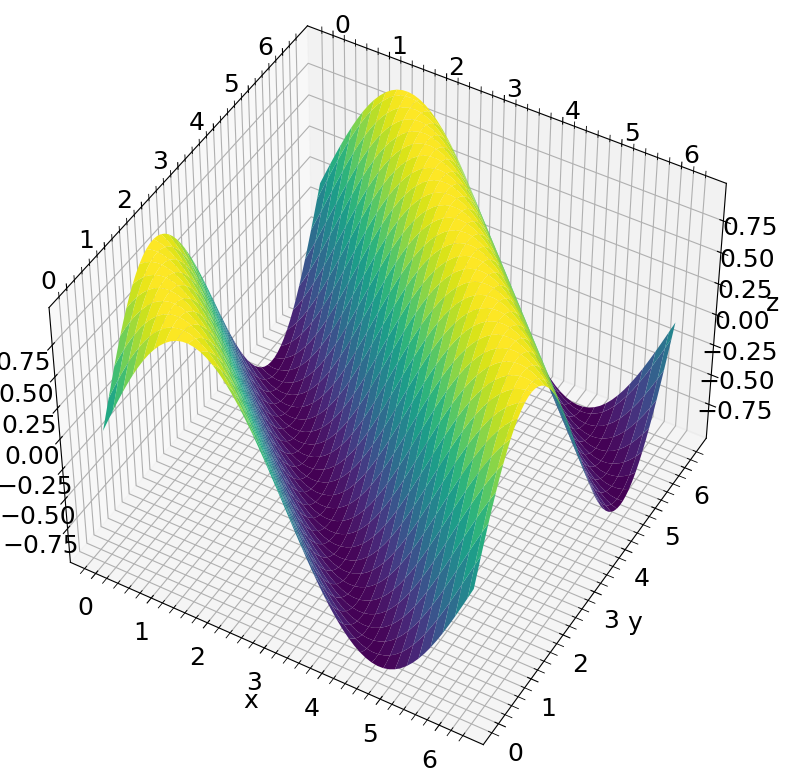

In [15]:
# Spatial grid
x3 = np.linspace(0, 2*np.pi, numpoints1space)
y3 = np.linspace(0, 2*np.pi, numpoints1space)
t3 = np.linspace(0, 4*np.pi, numpoints1time)  # time values for animation
X3, Y3, T3 = np.meshgrid(x3, y3, t3)

Z3 = np.sin(k5[0]*X3 + k5[1]*Y3 - omega5*T3)

# Set up figure and axis
fig3 = plt.figure(figsize=(10, 8))
ax3 = fig3.add_subplot(111, projection='3d')

# Initial surface
surf = ax3.plot_surface(X3[:,:,0], Y3[:,:,0], Z3[:,:,0], cmap='viridis')

# Set labels and title
ax3.set_xlabel('x')
ax3.set_ylabel('y')
ax3.set_zlabel('z')
# ax3.set_title('3D Plane Wave with Multiple Phase Surfaces')

# set the tick mark parameters
ax3.minorticks_on()
ax3.tick_params(which='both',direction="in",width=1)
ax3.tick_params(which='major',length=7)
ax3.tick_params(which='minor',length=3.5)
ax3.xaxis.set_ticks_position('both')
ax3.yaxis.set_ticks_position('both')
ax3.zaxis.set_ticks_position('both')

# # set axes limits
# ax3.set_xlim(0, 2*np.pi)
# ax3.set_ylim(0, 2*np.pi)



ax3.view_init(elev=45, azim=-60)

# show the plot
plt.tight_layout()
plt.show()


### Make interactive `matplotlib` animation

In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from ipywidgets import interact, FloatSlider

# --- 1. Define Data ---
# Define grid parameters
numpoints1space6 = 50  # Keep this moderate (30-50) for smooth FPS
omega3 = 1.0
k3 = [1.0, 1.0]

x6 = np.linspace(0, 2*np.pi, numpoints1space6)
y6 = np.linspace(0, 2*np.pi, numpoints1space6)
X6, Y6 = np.meshgrid(x6, y6) # Static spatial grid

# --- 2. Setup Figure ONCE ---
fig6 = plt.figure(figsize=(9, 6))

# Clean UI
fig6.canvas.header_visible = False
fig6.canvas.footer_visible = False

ax6 = fig6.add_subplot(111, projection='3d')
plt.subplots_adjust(left=0, bottom=0, right=1, top=1)

# Global variable to hold the surface object so we can remove it later
global_surf = None

# --- 3. Define Update Function ---
def update_surface(time):
    global global_surf
    
    # Calculate Z for the current time step
    Z3 = np.sin(k3[0]*X6 + k3[1]*Y6 - omega3*time)
    
    # Remove the old surface if it exists
    # (This is the trick for 3D animation in Matplotlib)
    if global_surf:
        global_surf.remove()
        
    # Plot the new surface
    # rcount/ccount controls downsampling; match numpoints1space6 to use full resolution
    # or set lower (e.g., 30) for faster rotation/rendering
    global_surf = ax6.plot_surface(X6, Y6, Z3, cmap='viridis', 
                                   rcount=numpoints1space6, ccount=numpoints1space6)

    # --- Formatting that must persist ---
    ax6.set_xlabel('x')
    ax6.set_ylabel('y')
    ax6.set_zlabel('z')
    
    # Fix limits so axes don't jitter
    ax6.set_zlim(-1.5, 1.5)
    ax6.set_xlim(0, 2*np.pi)
    ax6.set_ylim(0, 2*np.pi)
    
    # We do NOT call ax6.view_init() here, 
    # so the user can rotate the plot while the animation runs.

# --- 4. Initialize Static Elements ---
# One-time setup for ticks/styling that doesn't need re-running in loop
ax6.minorticks_on()
ax6.tick_params(which='major', length=7)
ax6.view_init(elev=45, azim=-60)

# --- 5. Create Slider and Run ---
slider6 = FloatSlider(min=0, max=4*np.pi, step=0.1, description='Time')
interact(update_surface, time=slider6);

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-01-planewave-3Dsurface_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-01.html) (direct link: [ch02-01-planewave-3Dsurface_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-01-planewave-3Dsurface_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.